In [50]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [51]:
tabela1 = pd.read_excel("preco_maca_2025.xlsx")
tabela2 = pd.read_excel("preco_maca_2026.xlsx")

In [52]:
tabela = pd.concat([tabela1, tabela2], ignore_index=True)
tabela

,Data da Coleta,Mês,Preço (R$)
0,2025-01-08,Janeiro,115.0
1,2025-01-15,Janeiro,112.5
2,2025-01-22,Janeiro,108.0
3,2025-01-29,Janeiro,105.0
4,2025-02-05,Fevereiro,98.0
...,...,...,...
90,2026-10-07,Outubro,168.0
91,2026-10-14,Outubro,170.0
92,2026-10-21,Outubro,172.0
93,2026-10-28,Outubro,175.0


In [53]:
lista = []
for meses in tabela["Mês"]:
    if meses == "Janeiro" or meses == "Fevereiro" or meses == "Março":
        lista.append("1º Trimestre")  
    elif meses == "Abril" or meses == "Maio" or meses == "Junho":
        lista.append("2º Trimestre")
    elif meses == "Julho" or meses == "Agosto" or meses == "Setembro":
        lista.append("3º Trimestre") 
    elif meses == "Outubro" or meses == "Novembro" or meses == "Dezembro":
        lista.append("4º Trimestre")
    else:
        print("Erro") 
        
tabela["Trimestre"] = lista

In [54]:
tabela["Período"] = tabela["Data da Coleta"].dt.to_period("Q")

In [55]:
tabela

,Data da Coleta,Mês,Preço (R$),Trimestre,Período
0,2025-01-08,Janeiro,115.0,1º Trimestre,2025Q1
1,2025-01-15,Janeiro,112.5,1º Trimestre,2025Q1
2,2025-01-22,Janeiro,108.0,1º Trimestre,2025Q1
3,2025-01-29,Janeiro,105.0,1º Trimestre,2025Q1
4,2025-02-05,Fevereiro,98.0,1º Trimestre,2025Q1
...,...,...,...,...,...
90,2026-10-07,Outubro,168.0,4º Trimestre,2026Q4
91,2026-10-14,Outubro,170.0,4º Trimestre,2026Q4
92,2026-10-21,Outubro,172.0,4º Trimestre,2026Q4
93,2026-10-28,Outubro,175.0,4º Trimestre,2026Q4


<Axes: xlabel='Preço (R$)', ylabel='Período'>

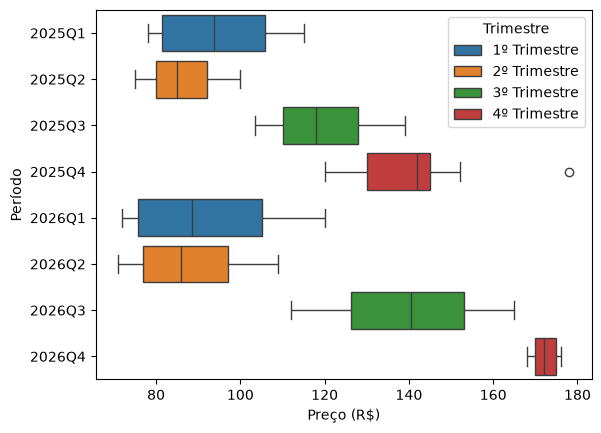

In [56]:
sns.boxplot(data = tabela, x = "Preço (R$)", y = "Período", hue = "Trimestre")



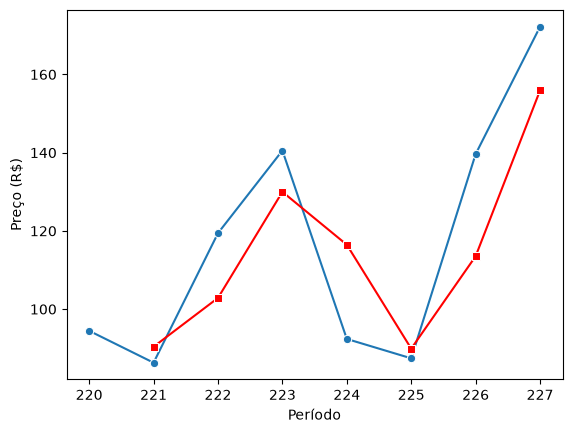

In [57]:
df_trimestral = (tabela.groupby("Período")["Preço (R$)"]
                 .mean()
                 .reset_index()
                 .sort_values("Período"))

df_trimestral["media_movel"] = df_trimestral["Preço (R$)"].rolling(window=2).mean()

sns.lineplot(
    
    data = df_trimestral,
    x = "Período",
    y = "Preço (R$)",
    marker = "o"
)

sns.lineplot(
    
    data = df_trimestral,
    x = "Período",
    y = "media_movel",
    marker = "s",
    color = "red"
)
plt.show()